# STO Ti-L dipole density matrix with pyms_plus

This example reads the bundled `structures/STO3bc.cif` and computes a projected Ti density matrix. The three analytic dipole transition potentials are a simplified model, and the matrix scale is arbitrary.

Run the notebook from the repository root using the Python 3 kernel in the virtual environment described in [README.md](README.md). Increase `thickness`, `gridshape` and `nT` for a larger simulation.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from pyms_plus.density_matrix import calculate_dm
from pyms_plus.density_matrix_setup import StructureASE, load_structure
from pyms_plus.Probe import wavev

structure_file = Path("structures/STO3bc.cif")
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "| structure:", structure_file)

Device: cpu | structure: structures/STO3bc.cif


## Specimen and dipole transition potentials

The CIF's third lattice vector is the beam direction. We repeat the short lateral direction three times and keep atoms within the requested thickness. The density-matrix routine expects the structure to contain only target atoms in that slab. `axis=1` keeps coherence along the repeated lateral direction.

In [2]:
eV = 200_000.0               # accelerating energy, eV
energy_loss = 456.0          # representative Ti L-edge loss, eV
thickness = 8.0              # angstrom
slice_thickness = 2.0        # angstrom
gridshape = (64, 48)
nT = 1                      # increase for frozen-phonon averaging

atoms = load_structure(structure_file, repeat=(1, 3, 1)).atoms
atoms = atoms[(atoms.positions[:, 2] >= 0) & (atoms.positions[:, 2] < thickness)]
cell = atoms.cell.array.copy()
cell[2, 2] = thickness
atoms.set_cell(cell, scale_atoms=False)
crystal = StructureASE(atoms)
assert len(crystal.get_target_positions(22)) > 0, "No Ti sites in the slab"
rsize = crystal.unitcell[:2]
print(f"{len(atoms)} atoms, {len(crystal.get_target_positions(22))} Ti sites; lateral size {rsize} Å")

# A simple three-channel dipole model in reciprocal space.
qy = np.fft.fftfreq(gridshape[0], d=rsize[0] / gridshape[0])[:, None]
qx = np.fft.fftfreq(gridshape[1], d=rsize[1] / gridshape[1])[None, :]
qz = wavev(eV) - wavev(eV - energy_loss)
theta = np.deg2rad(7.0)
denominator = qy**2 + qx**2 + qz**2
Hn0 = np.stack([
    np.fft.ifft2((qy * np.cos(theta) - qz * np.sin(theta)) / denominator),
    np.fft.ifft2(np.broadcast_to(qx, gridshape) / denominator),
    np.fft.ifft2((qy * np.sin(theta) + qz * np.cos(theta)) / denominator),
]).astype(np.complex64)
print("Transition potentials:", Hn0.shape)

246 atoms, 48 Ti sites; lateral size [31.545206 11.738103] Å
Transition potentials: (3, 64, 48)


## Propagate and form the density matrix

The three dipole channels add incoherently. `n`, `ell` and `epsilon` label the nominal Ti 2p transition; the supplied `Hn0` defines the actual transition model.

In [3]:
rho, rho_channels = calculate_dm(
    crystal, gridshape, eV, app=None, thicknesses=thickness,
    Ztarget=22, n=2, ell=1, epsilon=1, Hn0=Hn0,
    slice_thickness=slice_thickness, device_type=device,
    nT=nT, axis=1, return_components=True, showProgress=True,
)
assert rho.shape == (gridshape[1], gridshape[1])
assert np.all(np.isfinite(rho))
assert np.allclose(rho, rho_channels.sum(axis=0), rtol=2e-5, atol=1e-8)
assert np.allclose(rho, rho.conj().T, rtol=1e-4, atol=1e-8)
print("Density matrix:", rho.shape, "| trace:", float(np.trace(rho).real))

Frozen phonon iterations::   0%|          | 0/1 [00:00<?, ?it/s]

Making projected potentials:   0%|          | 0/1 [00:00<?, ?it/s]

Making projected potentials: 100%|██████████| 1/1 [00:01<00:00,  1.45s/it]

Making projected potentials: 100%|██████████| 1/1 [00:01<00:00,  1.45s/it]

Density-matrix slices:   0%|          | 0/4 [00:00<?, ?it/s]

Density-matrix slices: 100%|██████████| 4/4 [00:00<00:00, 118.73it/s]


Frozen phonon iterations:: 100%|██████████| 1/1 [00:01<00:00,  1.49s/it]

Frozen phonon iterations:: 100%|██████████| 1/1 [00:01<00:00,  1.49s/it]

Density matrix: (48, 48) | trace: 0.0006040395237505436


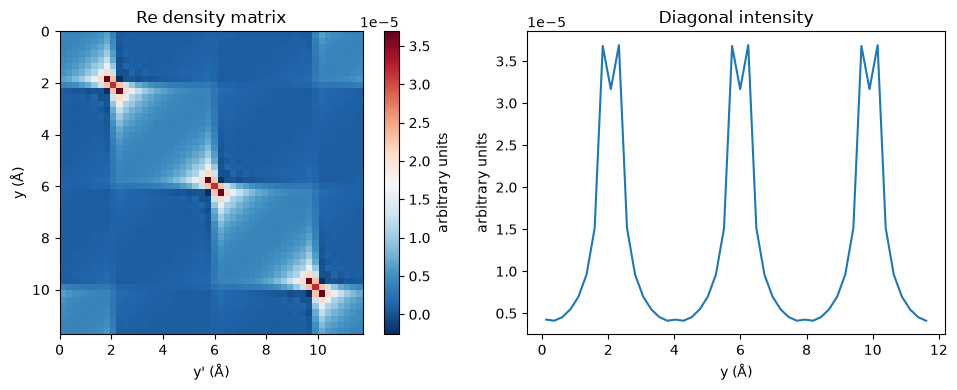

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
extent = [0, rsize[1], rsize[1], 0]
im = axes[0].imshow(rho.real, origin="upper", extent=extent, cmap="RdBu_r")
axes[0].set(title="Re density matrix", xlabel="y' (Å)", ylabel="y (Å)")
fig.colorbar(im, ax=axes[0], label="arbitrary units")
y = (np.arange(rho.shape[0]) + 0.5) * rsize[1] / rho.shape[0]
axes[1].plot(y, np.diag(rho).real)
axes[1].set(title="Diagonal intensity", xlabel="y (Å)", ylabel="arbitrary units")
fig.tight_layout()
plt.show()